# clock/10 — goal heads vs FV (function-vector) heads

Do the **goal heads** (trained GoalScope / head-mask set) and the **function-vector heads**
(Todd et al. 2024 localization) coincide, or are they dissociable populations?

1. **Load FV heads** — from either (i) the CMA / AIE sweep (`aie_*.pt`, top-K) or
   (ii) the joint head mask (`head_mask/all_lam*/mask.pt`, thresholded).
2. **FV-effect sanity check** — transplant the top FV heads' mean activation `ā` into a
   *zero-shot* ICL query and check it recovers the target relation's answer, on a few tasks.
   (Canonical Todd et al. FV-recovery test, reusing the CMA transplant primitive
   `forward_with_src_replacement`.)
3. **Dissociation**
   - **3a** location + overlap between FV heads and goal heads (grid plot + Jaccard).
   - **3b** `apply_goalscope` on the *same* code prompt with **only** `selected_heads` swapped
     (FV heads vs goal heads) — qualitative. Oracle-based scale-up deferred.

Setup mirrors `09.1_goalhead_gaze` (32B, eager attention).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-07-18 18:27:16 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-18 18:27:16 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-18 18:27:16 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-18 18:27:16 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-18 18:27:16 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-18 18:27:17 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-18 18:27:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-18 18:27:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-18 18:27:42 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## Head sets — goal heads + FV heads

**Goal heads**: trained localization mask, thresholded @0.9, restricted to the 32B goal band
(layers 25–55), exactly as in `09.1` / `09 §4`.

**FV heads**: `FV_SOURCE` switch — `"cma"` takes the top-`FV_TOPK` heads by AIE; `"mask"` thresholds
the joint FV head mask for a chosen `λ`.

In [3]:
# ── goal heads (trained mask @0.9, 32B band 25-55) ──
GOAL_THRESHOLD = 0.9
GOAL_BAND = (25, 56)                       # keep layers [25, 56); mirrors 09.1
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads (@{GOAL_THRESHOLD}, band {GOAL_BAND[0]}-{GOAL_BAND[1]-1}): {len(goal_heads)}")

goal heads (@0.9, band 25-55): 122


In [26]:
# ── FV heads: CMA top-K  OR  joint-mask threshold ──
FV_SOURCE         = "cma"        # "cma" (top-K AIE) | "mask" (thresholded joint mask)
FV_TOPK           = 150           # cma: number of top-AIE heads (Todd et al. default)
FV_MASK_LAM       = "1"         # mask: which lambda sweep dir (all_lam{LAM})
FV_MASK_THRESHOLD = 0.5          # mask: selection threshold

fv_dir = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "fv", MODEL_NAME.split("/")[-1])
if FV_SOURCE == "cma":
    aie = torch.load(os.path.join(fv_dir, "aie_all_ns10_nt25.pt"),
                     map_location="cpu")["aie"].numpy()                 # (L, H)
    top = np.argsort(aie, axis=None)[::-1][:FV_TOPK]
    fv_heads = [(int(i // N_HEADS), int(i % N_HEADS)) for i in top]
    fv_desc = f"CMA top-{FV_TOPK} AIE"
elif FV_SOURCE == "mask":
    mck = torch.load(os.path.join(fv_dir, "head_mask", f"all_lam{FV_MASK_LAM}", "mask.pt"),
                     map_location="cpu", weights_only=False)
    fv_layers = [int(x) for x in mck["layers"]]
    fmv = mck["mask_values"].numpy()
    fv_heads = [(fv_layers[li], int(h)) for li, h in np.argwhere(fmv > FV_MASK_THRESHOLD)]
    fv_desc = f"mask lam{FV_MASK_LAM} @{FV_MASK_THRESHOLD}"
else:
    raise ValueError(FV_SOURCE)
print(f"FV heads ({fv_desc}): {len(fv_heads)}")
print("  ", ", ".join(f"L{l}H{h}" for l, h in sorted(fv_heads)))

FV heads (CMA top-150 AIE): 150
   L0H33, L29H26, L29H27, L29H29, L35H34, L36H36, L38H9, L38H15, L39H19, L39H36, L40H6, L40H34, L41H1, L41H7, L41H24, L41H26, L41H27, L41H29, L41H33, L41H39, L42H22, L43H1, L43H4, L43H9, L43H12, L43H18, L43H19, L43H20, L43H21, L43H24, L44H0, L44H4, L44H7, L44H9, L44H12, L44H14, L44H16, L44H20, L44H21, L44H22, L44H24, L44H28, L44H38, L45H3, L45H7, L45H12, L45H14, L45H15, L45H18, L45H25, L45H26, L45H27, L45H28, L45H29, L45H32, L45H34, L45H35, L45H37, L46H2, L46H6, L46H9, L46H14, L46H17, L46H18, L46H19, L46H20, L46H22, L46H25, L46H28, L46H29, L46H32, L46H37, L47H1, L47H2, L47H12, L47H15, L47H17, L47H18, L47H21, L47H27, L47H28, L47H30, L47H31, L47H35, L48H1, L48H12, L48H16, L48H19, L48H25, L48H26, L48H30, L48H33, L49H0, L49H5, L49H7, L49H9, L49H26, L49H27, L49H28, L49H31, L50H12, L50H20, L50H21, L50H23, L50H24, L50H31, L50H33, L51H0, L51H10, L51H13, L51H19, L51H22, L51H30, L51H32, L51H33, L52H9, L52H31, L52H32, L54H14, L54H30, L54H36, L54H37, L54H38, L55H20,

## 2. FV-effect sanity check

For a handful of relations, transplant the **top FV heads' mean activation `ā`** (per task,
computed over clean 10-shot ICL prompts) into a **zero-shot** query `Q: x⏎A:` at the last token,
and check the top predicted token flips toward the correct answer. This is the Todd et al.
function-vector recovery test, using the same `forward_with_src_replacement` head-transplant
primitive the CMA localization uses.

Reports, per task: **clean** vs **patched** top-1 accuracy and mean Δp(correct), plus a few
concrete `input → (clean top | patched top)` examples.

In [27]:
from scripts.fv.fv_common import (load_fv_task, build_icl_prompt,
                                   first_answer_token_id, compute_mean_head_activations)
from src.goals.head_loc_attn import HeadMask, forward_with_src_replacement
from src.tokens import prepare_input

FV_TASKS    = ["antonym", "country-capital", "present-past", "singular-plural"]
N_QUERY     = 20         # zero-shot queries per task
MEAN_TRIALS = 25         # clean ICL prompts for a-bar per task
FV_LAYERS   = list(range(N_LAYER))

# binary HeadMask (1.0 at the FV heads) over all layers
fv_mask = HeadMask(N_LAYER, N_HEADS)
with torch.no_grad():
    fv_mask.values.zero_()
    for (l, h) in fv_heads: fv_mask.values[l, h] = 1.0

def zero_shot(x): return build_icl_prompt([], x)          # "\n\nQ: x\nA:"

rows = []
for t in FV_TASKS:
    task = load_fv_task(t, seed=42)
    a_bar = compute_mean_head_activations(mt, task, FV_LAYERS, n_shots=10,
                                          n_trials=MEAN_TRIALS, batch_size=16, seed=42)  # (L, n_embd)
    qs = task.valid[:N_QUERY]
    clean_hit = patch_hit = 0; dp_sum = 0.0; ex = []
    for q in qs:
        prompt = zero_shot(q["input"])
        tid = first_answer_token_id(mt, prompt, q["output"])
        inp = prepare_input(prompts=prompt, tokenizer=mt)
        with torch.inference_mode():
            cl = mt._model(**dict(inp)).logits[:, -1, :].float()
            pl = forward_with_src_replacement(mt, inp, a_bar, fv_mask, layers=FV_LAYERS,
                                              alpha=1.0, patch_positions=[-1]).float()
        if pl.ndim == 1: pl = pl.unsqueeze(0)
        cp = torch.softmax(cl, -1)[0]; pp = torch.softmax(pl, -1)[0]
        clean_hit += int(cp.argmax().item() == tid)
        patch_hit += int(pp.argmax().item() == tid)
        dp_sum += float(pp[tid].item() - cp[tid].item())
        if len(ex) < 3:
            ex.append((q["input"], q["output"],
                       mt.tokenizer.decode([cp.argmax().item()]).strip(),
                       mt.tokenizer.decode([pp.argmax().item()]).strip()))
    rows.append(dict(task=t, n=len(qs), clean=clean_hit/len(qs), patch=patch_hit/len(qs),
                     dP=dp_sum/len(qs), ex=ex))
    logger.info(f"[{t}] clean {clean_hit}/{len(qs)}  patch {patch_hit}/{len(qs)}")

tbl = Table(title=f"FV recovery ({fv_desc}) — zero-shot query + FV transplant")
for c in ["task", "n", "clean top-1", "patch top-1", "mean dP(correct)"]:
    tbl.add_column(c, justify=("left" if c == "task" else "right"))
for r in rows:
    tbl.add_row(r["task"], str(r["n"]), f"{r['clean']:.2f}", f"{r['patch']:.2f}", f"{r['dP']:+.3f}")
rich_print(tbl)
for r in rows:
    rich_print(f"[bold]{r['task']}[/bold]")
    for x, y, c, p in r["ex"]:
        rich_print(f"   {x!r} -> correct={y!r}   clean={c!r}   patch={p!r}")

2026-07-18 20:08:32 __main__ INFO     [antonym] clean 0/20  patch 9/20
2026-07-18 20:08:37 __main__ INFO     [country-capital] clean 3/20  patch 12/20
2026-07-18 20:08:42 __main__ INFO     [present-past] clean 0/20  patch 19/20
2026-07-18 20:08:47 __main__ INFO     [singular-plural] clean 1/20  patch 20/20


    FV recovery (CMA top-150 AIE) — zero-shot query + FV transplant    
┏━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ task            ┃  n ┃ clean top-1 ┃ patch top-1 ┃ mean dP(correct) ┃
┡━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ antonym         │ 20 │        0.00 │        0.45 │           +0.320 │
│ country-capital │ 20 │        0.15 │        0.60 │           +0.419 │
│ present-past    │ 20 │        0.00 │        0.95 │           +0.896 │
│ singular-plural │ 20 │        0.05 │        1.00 │           +0.894 │
└─────────────────┴────┴─────────────┴─────────────┴──────────────────┘

antonym

'comic' -> correct='tragic'   clean='A'   patch='comic'

'transparent' -> correct='opaque'   clean='Transparent'   patch='opaque'

'fore' -> correct='aft'   clean='It'   patch='aft'

... (8 outputs left out)

singular-plural

'sofa' -> correct='sofas'   clean='A'   patch='sofas'

'helicopter' -> correct='helicopters'   clean='aircraft'   patch='helicopters'

'pencil' -> correct='pencils'   clean='writing'   patch='pencils'

## 3a. Location + overlap between FV heads and goal heads

goal heads: 122  FV heads: 150  intersection: 23  union: 249  Jaccard: 0.092


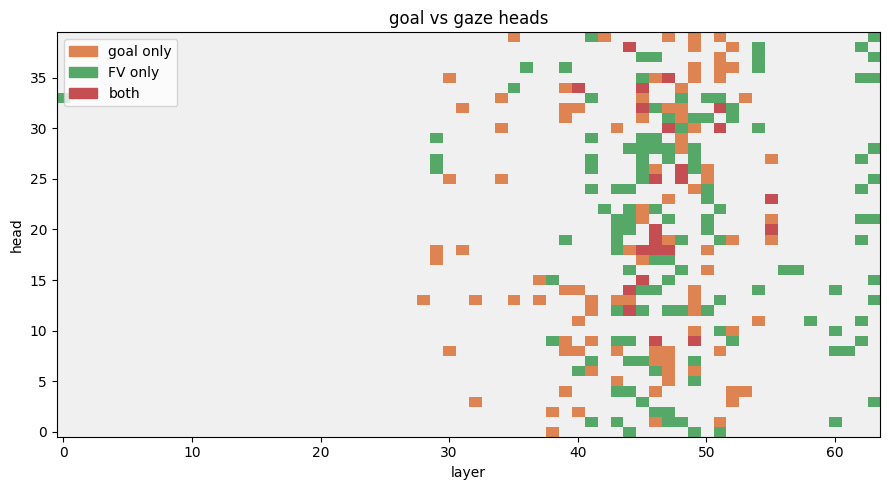

                                              goal vs FV head overlap                                              
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ metric        ┃                                                                                           value ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ goal heads    │                                                                                             122 │
│ FV heads      │                                                                                             150 │
│ intersection  │                                                                                              23 │
│ union         │                                                                                             249 │
│ Jaccard       │                                                                                           0.092 │
│ overlap heads │  L40H34, L44H12, L44H14, L44H38, L45H15, L45H18, L45H32, L45H34, L46H9, L46H18, L46H19, L46H20, │
│               │           L46H25, L47H18, L47H30, L47H35, L48H25, L48H26, L49H9, L51H30, L51H32, L55H20, L55H23 │
└───────────────┴─────────────────────────────────────────────────────────────────────────────────────────────────┘

In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

gset, fset = set(goal_heads), set(fv_heads)
inter, union = gset & fset, gset | fset
jacc = len(inter) / len(union) if union else 0.0
print(f"goal heads: {len(gset)}  FV heads: {len(fset)}  intersection: {len(inter)}  union: {len(union)}  Jaccard: {jacc:.3f}")

grid = np.zeros((N_LAYER, N_HEADS))
for (l, h) in goal_heads: grid[l, h] += 1        # 1 = goal
for (l, h) in fv_heads:   grid[l, h] += 2        # 2 = FV, 3 = both
cmap = ListedColormap(["#f0f0f0", "#dd8452", "#55a868", "#c44e52"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.T, aspect="auto", cmap=cmap, vmin=0, vmax=3, origin="lower")
ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title("goal vs gaze heads")
ax.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                   [("#dd8452","goal only"),("#55a868","FV only"),("#c44e52","both")]], loc="upper left")
plt.tight_layout(); plt.show()


ot = Table(title="goal vs FV head overlap")
ot.add_column("metric"); ot.add_column("value", justify="right")
ot.add_row("goal heads", str(len(goal_heads)))
ot.add_row("FV heads", str(len(fv_heads)))
ot.add_row("intersection", str(len(inter)))
ot.add_row("union", str(len(union)))
ot.add_row("Jaccard", f"{jacc:.3f}")
ot.add_row("overlap heads", ", ".join(f"L{l}H{h}" for l, h in sorted(inter)) or "—")
rich_print(ot)

## 3b. GoalScope — swap **only** the heads (FV vs goal)

One shared code prompt + generation, one shared `GOALSCOPE_KWARGS` dict (tweak freely). The two
runs differ **only** in `selected_heads`: FV heads vs goal heads. `strategy="replace"` steers each
set at its *own* layers. Eyeball the two token-hover verbalizations for a qualitative dissociation;
Oracle-based scale-up comes later.

In [44]:
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.functional import generate_with_patch
from rich.markup import escape

dest_example = build_example(
    mt=mt,
    rng=random.Random(1234),
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="multiline",
    naming="natural"
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_prompt = dest_prompt[: dest_prompt.index("def check_conditions(n: int):")]
print(dest_prompt)

# chunky_sample = next(s for s in chunky_samples if s.spec.datatype == "str")
# dest_prompt = build_prompt(chunky_sample)

dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    



clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n):
    p=1
    for d in str(n):p*=int(d)
    a=p>0
    b=int(n**0.5)**2==n
    c=n%2==0
    d=n%4==0
    print(f"Product of digits > 0: {a}, Perfect square: {b}, Even: {c}, Divisible by 4: {d}, All conditions: {a and
b and c and d}")
</code>

In [47]:
from src.goals.goalscope import apply_goalscope

# ── common GoalScope kwargs — tweak here; ONLY `selected_heads` differs between runs ──
GOALSCOPE_KWARGS = dict(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    strategy="replace", alpha=1.0,
    # strategy="additive", alpha=0.2,
    steer_layer_range=(35, 46),
    batch_size=32,
    max_new_tokens=64,
    show=True,
    include_noncode=True,
)

fv_scope = apply_goalscope(
    selected_heads=sorted(fv_heads),
    title=f"GoalScope — FV heads ({fv_desc})",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/4 [00:00<?, ?it/s]

In [48]:
goal_scope = apply_goalscope(
    selected_heads=sorted(goal_heads),
    title="GoalScope — Goal heads",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/4 [00:00<?, ?it/s]

In [49]:
messages = [
    {"role": "system", "content": "You are a helpful assistant proficient in programming."},
    {"role": "user", "content": "Write a mergesort code in Python. Just the code, no explanation and comments."},
    {"role": "assistant", "content": "\n<code>\n"},
]
dest_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,
    continue_final_message=True,
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},
)
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean         <|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
Write a mergesort code in Python. Just the code, no explanation and comments.<|im_end|>
<|im_start|>assistant

<code>
def merge_sort(arr):
    if len(arr) > 1:
        mid = len(arr) // 2
        L = arr[:mid]
        R = arr[mid:]

        merge_sort(L)
        merge_sort(R)

        i = j = k = 0

        while i < len(L) and j < len(R):
            if L[i] < R[j]:
                arr[k] = L[i]
                i += 1
            else:
                arr[k] = R[j]
                j += 1
            k += 1

        while i < len(L):
            arr[k] = L[i]
            i += 1
            k += 1

        while j < len(R):
            arr[k] = R[j]
            j += 1
            k += 1
</code>

In [50]:
from src.goals.goalscope import apply_goalscope

# ── common GoalScope kwargs — tweak here; ONLY `selected_heads` differs between runs ──
GOALSCOPE_KWARGS = dict(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    strategy="replace", alpha=1.0,
    # strategy="additive", alpha=0.2,
    steer_layer_range=(35, 46),
    batch_size=32,
    max_new_tokens=64,
    show=True,
    include_noncode=True,
)

fv_scope = apply_goalscope(
    selected_heads=sorted(fv_heads),
    title=f"GoalScope — FV heads ({fv_desc})",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/7 [00:00<?, ?it/s]

In [51]:
goal_scope = apply_goalscope(
    selected_heads=sorted(goal_heads),
    title="GoalScope — Goal heads",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/7 [00:00<?, ?it/s]